# PRESET tutorial

**Differential expression with a prior learned across RNA-seq experiments.**

PRESET is a prior-fitted network. It was trained once on simulated experiments, real backgrounds with planted effects and real two-group cohorts with labels from held-out samples, and it returns a posterior for every gene in a single forward pass. The sections below follow the paper.

| | Section | Paper |
|---|---|---|
| 1 | Setup | |
| 2 | Input data | Methods · Problem formulation |
| 3 | Run PRESET | Methods · Step 2 |
| 4 | The posterior of a gene | Methods · Step 2 (spike-and-slab posterior) |
| 5 | A DEG list with its expected false discoveries | Methods · Step 3 |
| 6 | Expected vs realised false discoveries | Results · Planted effects |
| 7 | Effect sizes | Results · Effect sizes against external measurements |
| 8 | Outlier counts | Results · Null comparisons and outlying counts |
| 9 | Agreement with the rest of the cohort | Results · Held-out cohorts |
| 10 | Pathways | Results · Pathways in a held-out psoriasis cohort |
| 11 | Volcano plot and gene embedding | Supplementary (embedding maps) |
| 12 | Scope and self-check | Discussion |

Runs on a laptop CPU in a few minutes; no R installation is needed.

## 1. Setup

In [1]:
# git clone git@github.com:wodus1035/PRESET.git && cd PRESET && pip install ".[tutorial]"
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import preset

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
BLUE, GREY, RED, INK = "#2a78d6", "#8a8a86", "#d63a2f", "#2b2b2b"

model, device, info = preset.load_model()        # the weights ship with the package
print(f"PRESET {preset.__version__} | {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters | device: {device}")

PRESET 1.0.0 | 2.49 M parameters | device: cpu


## 2. Input data

PRESET needs **raw counts** (samples × genes) and a **0/1 condition** per sample. The example is GSE121212: skin biopsies of healthy donors and psoriasis lesions. PRESET never saw this cohort during training.

In [2]:
counts = pd.read_csv("data/GSE121212_skin_counts.tsv.gz", sep="\t", index_col=0)   # genes x samples
samples = pd.read_csv("data/GSE121212_skin_samples.tsv", sep="\t", index_col=0)
counts = counts.drop(index=["MT-RNR1", "MT-RNR2"])        # quality control used in the paper: remove mitochondrial rRNA
print(f"{counts.shape[0]:,} genes x {counts.shape[1]} samples")
samples.group.value_counts()

31,358 genes x 66 samples


group
healthy      38
psoriasis    28
Name: count, dtype: int64

A small study: **4 healthy vs 4 psoriasis**. The other 58 samples are kept aside as a reference (Section 9).

In [3]:
rng = np.random.default_rng(1)
healthy = rng.permutation(samples.index[samples.group == "healthy"])
psoriasis = rng.permutation(samples.index[samples.group == "psoriasis"])
study = list(healthy[:4]) + list(psoriasis[:4])
cond = np.array([0, 0, 0, 0, 1, 1, 1, 1])                 # 1 = psoriasis

# Give PRESET every gene with a count; low-count genes inform the dataset-level offset.
# `expressed` marks the genes that are ranked and reported.
X, genes, prep, expressed = preset.io.prepare(counts[study].T)
X = pd.DataFrame(X, index=study, columns=genes)
prep

{'n_samples': 8,
 'n_genes_in': 31358,
 'n_genes_kept': 25741,
 'n_genes_expressed': 20593,
 'context_rule': 'cap',
 'median_library': 17477085}

## 3. Run PRESET

One forward pass. Nothing is fitted to this dataset.

In [4]:
t0 = time.time()
res = preset.run(X, cond, report=expressed, model=model, params=True)
print(f"{len(res):,} genes in {time.time() - t0:.1f} s")
cols = ["gene", "mean_count", "p_de", "lfc_mean", "lfc_given_de", "expected_false_in_list", "bayes_fdr"]
res.sort_values("rank")[cols].head(8).round(3)

25,741 genes in 21.4 s


,gene,mean_count,p_de,lfc_mean,lfc_given_de,expected_false_in_list,bayes_fdr
8886,HEPHL1,6567.500,1.0,9.063,9.064,0.000,0.0
21957,SPRR2D,8337.375,1.0,7.054,7.055,0.000,0.0
9438,IFI27,7124.000,1.0,6.659,6.659,0.000,0.0
23199,TMPRSS11D,839.125,1.0,7.486,7.486,0.000,0.0
14008,PI3,13994.625,1.0,9.999,10.000,0.001,0.0
10452,KYNU,1255.125,1.0,5.636,5.637,0.001,0.0
13272,OASL,634.625,1.0,6.872,6.872,0.001,0.0
15532,RHCG,4391.875,1.0,9.907,9.908,0.001,0.0


| Column | Meaning |
|---|---|
| `p_de` | $P(\lvert\log_2\mathrm{FC}\rvert > 0.5)$: probability of a change of meaningful size |
| `lfc_mean` | posterior mean $\log_2$ fold change |
| `lfc_given_de` | effect size if the gene changes |
| `expected_false_in_list` | expected number of false discoveries if you take this gene and every gene above it |
| `bayes_fdr` | the same, as a fraction of the list |

## 4. The posterior of a gene

$$q(\theta_g) = \pi_{0g}\,\delta_0(\theta_g) + (1-\pi_{0g})\; t_4(\theta_g;\, m_g, s_g)$$

A point mass at zero (no change) plus a Student-*t* slab (the change, if there is one). `p_de` is the slab mass beyond ±0.5 (shaded).

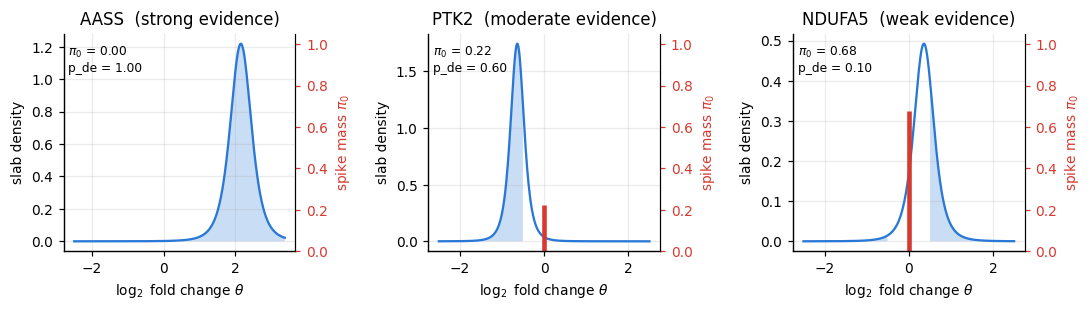

In [5]:
from math import gamma, pi, sqrt

def t_pdf(x, df, loc, scale):
    z = (x - loc) / scale
    return gamma((df + 1) / 2) / (gamma(df / 2) * sqrt(df * pi) * scale) * (1 + z ** 2 / df) ** (-(df + 1) / 2)

r = res[expressed & (res.mean_count > 100) & res.gene.str.fullmatch(r"[A-Z][A-Z0-9]+") & ~res.gene.str.match(r"G\d")]   # named genes
picks = {"strong evidence": r.loc[r.p_de > 0.99].sort_values("mean_count").iloc[len(r.loc[r.p_de > 0.99]) // 2],
         "moderate evidence": r.iloc[(r.p_de - 0.6).abs().argmin()],
         "weak evidence": r.iloc[(r.p_de - 0.1).abs().argmin()]}

fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
for ax, (title, g) in zip(axes, picks.items()):
    x = np.linspace(min(-2.5, g.slab_loc - 4 * g.slab_scale), max(2.5, g.slab_loc + 4 * g.slab_scale), 600)
    y = (1 - g.pi0) * t_pdf(x, g.slab_df, g.slab_loc, g.slab_scale)
    ax.plot(x, y, color=BLUE); ax.fill_between(x, y, where=np.abs(x) > 0.5, color=BLUE, alpha=0.25, lw=0)
    ax.set(title=f"{g.gene}  ({title})", xlabel=r"$\log_2$ fold change $\theta$", ylabel="slab density")
    spike = ax.twinx(); spike.vlines(0, 0, g.pi0, color=RED, lw=3); spike.set_ylim(0, 1.05); spike.grid(False)
    spike.set_ylabel(r"spike mass $\pi_0$", color=RED); spike.spines["right"].set_visible(True); spike.tick_params(axis="y", colors=RED)
    ax.text(0.02, 0.95, f"$\\pi_0$ = {g.pi0:.2f}\np_de = {g.p_de:.2f}", transform=ax.transAxes, va="top", fontsize=8)
fig.tight_layout()

## 5. A DEG list with its expected false discoveries

$$\mathbb{E}[V(S_k)] = \sum_{g \in S_k} \bigl(1 - P_g(0.5)\bigr)$$

Every list comes with the number of false discoveries it is expected to contain, before any validation. The default calls (`rule="auto"`) depend on the size of the smaller group. Below 16 samples, as here, they use a target-decoy FDR: decoy genes, real genes whose samples are re-split so that both groups hold the same mix of healthy and psoriasis samples, are scored together with the real genes in eight extra passes, and the cut-off is set by how many of them pass. One decoy more than observed is always counted, as in knockoff+, so a dataset in which nothing changes gets no calls; the shortest list that can be called at 5% is then 10 genes. From 16 samples per group the default switches to the Bayesian FDR shown below, which also counts genes changed by less than the threshold; decoys stand only for genes that do not change at all.

The posterior columns (`p_de`, `lfc_mean`, `bayes_fdr`) come from the first pass, without decoys; the decoy passes only set the cut-off.

3,442 genes called; expected false discoveries among them: 222 (6.4%)


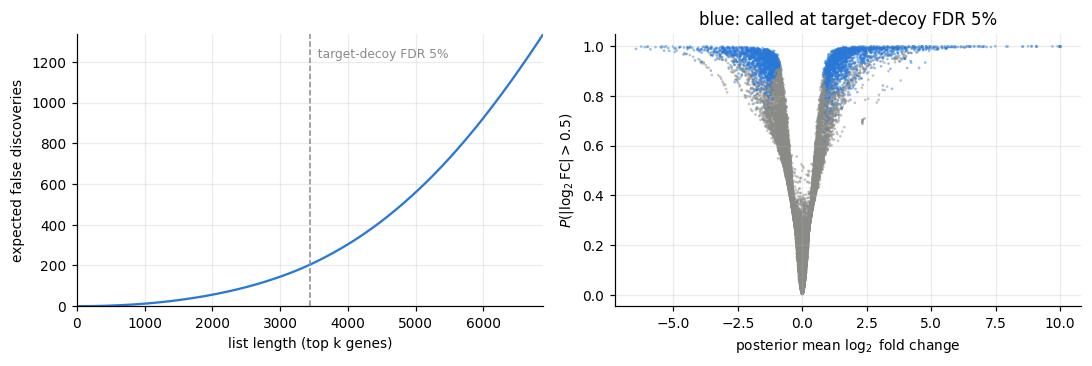

In [6]:
called = preset.calls(res, fdr=0.05)                     # default rule "auto": target-decoy FDR <= 5% here (fewer than 16 per group)
n_called, efd = int(called.sum()), (1 - res.p_de[called]).sum()
print(f"{n_called:,} genes called; expected false discoveries among them: {efd:.0f} ({efd / n_called:.1%})")

ranked = res.dropna(subset=["rank"]).sort_values("rank")
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
a.plot(ranked["rank"], ranked.expected_false_in_list, color=BLUE)
a.set(xlabel="list length (top k genes)", ylabel="expected false discoveries", xlim=(0, 2 * n_called), ylim=(0, ranked.expected_false_in_list.iloc[2 * n_called]))
a.axvline(n_called, color=GREY, ls="--", lw=1); a.text(n_called, 0.95, "  target-decoy FDR 5%", color=GREY, fontsize=8, transform=a.get_xaxis_transform(), va="top")

b.scatter(res.lfc_mean, res.p_de, s=3, c=np.where(called, BLUE, GREY), alpha=0.5, lw=0, rasterized=True)
b.set(xlabel=r"posterior mean $\log_2$ fold change", ylabel=r"$P(|\log_2\mathrm{FC}| > 0.5)$", title="blue: called at target-decoy FDR 5%")
fig.tight_layout()

Asking for larger changes only needs another run with `tau`. The ranking and `p_de` are valid for any threshold, but the calling rules were validated at the default of 0.5: with `tau=1` the target-decoy list exceeded its 5% target from 8 samples per group in our tests, so treat calls at other thresholds as approximate.

In [7]:
res_tau1 = preset.run(X, cond, report=expressed, model=model, tau=1.0)
print(f"P(|log2FC| > 1) > 0.9 for {(res_tau1.p_de > 0.9).sum():,} genes; "
      f"called at target-decoy FDR 5%: {preset.calls(res_tau1, fdr=0.05).sum():,}")

P(|log2FC| > 1) > 0.9 for 1,305 genes; called at target-decoy FDR 5%: 2,811


The Bayesian FDR of the same ranking, `bayes_fdr`, is the posterior's own estimate and needs no extra pass:

In [8]:
bayes = preset.calls(res, fdr=0.05, rule="bfdr")
print(f"called at target-decoy FDR 5%: {called.sum():,}; at Bayesian FDR 5%: {bayes.sum():,} ({(bayes & called).sum():,} in both lists)")

called at target-decoy FDR 5%: 3,442; at Bayesian FDR 5%: 3,076 (2,966 in both lists)


The decoy cut-off is set by the data rather than by the posterior: it is stricter where the posterior is overconfident (planted effects, Section 6) and looser where it is cautious, as on this cohort (Section 9).

## 6. Expected vs realised false discoveries

A ground truth from a real background. Healthy samples not used above are split at random into 4 vs 4, so the true effect is zero. Effects are then planted in 10% of genes by **binomial thinning**: each read of the lower group is kept with probability $2^{-|\theta|}$. The noise stays real and the truth is known.

In [9]:
def plant(C, cond, frac=0.10, seed=0):
    # C: genes x samples (integer counts). Returns the thinned counts and the true log2 fold change of every gene.
    rng = np.random.default_rng(seed)
    C, theta = C.copy(), np.zeros(C.shape[0])
    de = rng.choice(C.shape[0], int(frac * C.shape[0]), replace=False)
    theta[de] = rng.choice([-1, 1], len(de)) * rng.uniform(0.5, 3.0, len(de))
    for sign, lower in ((1, 0), (-1, 1)):                  # up in cases -> thin the controls, and vice versa
        g, s = de[np.sign(theta[de]) == sign], np.where(cond == lower)[0]
        C[np.ix_(g, s)] = rng.binomial(C[np.ix_(g, s)], 2.0 ** -np.abs(theta[g])[:, None])
    return C, theta

def analyse(C, cond, names, theta, decoy=False):
    Xp, gp, _, ep = preset.io.prepare(pd.DataFrame(C.T, columns=names))
    rp = preset.run(pd.DataFrame(Xp, columns=gp), cond, report=ep, model=model, decoy=decoy)
    rp["theta"] = pd.Series(theta, index=names)[gp].to_numpy(); rp["expressed"] = ep
    return rp

pool, c8, runs = healthy[4:], np.array([0, 0, 0, 0, 1, 1, 1, 1]), []
for rep in range(6):
    s8 = np.random.default_rng(100 + rep).choice(pool, 8, replace=False)
    C, theta = plant(counts[s8].to_numpy(), c8, seed=rep)
    runs.append(dict(samples=s8, counts=C, theta=theta, res=analyse(C, c8, counts.index, theta, decoy=True)))

calls_ = []
for i, run in enumerate(runs):
    rp = run["res"]; false = rp.theta.abs() <= 0.5; truth = rp.expressed & ~false
    for rule, call in (("target-decoy FDR 5%", preset.calls(rp, fdr=0.05, rule="decoy")), ("Bayesian FDR 5%", preset.calls(rp, fdr=0.05, rule="bfdr")),
                       ("P > 0.9", preset.calls(rp, rule="p"))):
        calls_.append(dict(rule=rule, rep=i, called=int(call.sum()), realised_fdr=false[call].mean(), power=(call & truth).sum() / truth.sum()))
pd.DataFrame(calls_).groupby("rule", sort=False)[["called", "realised_fdr", "power"]].mean().round(3)

,called,realised_fdr,power
rule,,,
target-decoy FDR 5%,1295.333,0.024,0.651
Bayesian FDR 5%,1566.667,0.067,0.754
P > 0.9,1311.000,0.020,0.649


With planted effects the Bayesian list contains more false discoveries than its 5% target; the target-decoy list stays below it, with fewer calls.

For a list of the top $k$ genes, the posterior implies not only the expected number of false discoveries but also its range: each gene is false with probability $1-P_g$. False-discovery counts are integers, so an expected 0.3 can only be realised as 0, 1, 2, ...; compare each count with its range, not with a ratio.

In [10]:
sim, rows = np.random.default_rng(0), []
for i, run in enumerate(runs):
    rp = run["res"]; false = (rp.theta.abs() <= 0.5).to_numpy(); rank = rp["rank"].to_numpy(); q = 1 - rp.p_de.to_numpy()
    for k in (500, 1000, 1500, 2000):
        top = rank <= k
        draws = (sim.random((2000, top.sum())) < q[top]).sum(1)          # false discoveries implied by the posterior
        lo, hi = np.percentile(draws, [5, 95])
        rows.append(dict(rep=i, k=k, expected=q[top].sum(), realised=int(false[top].sum()), lo=lo, hi=hi))
efd = pd.DataFrame(rows); efd["inside_90"] = efd.realised.between(efd.lo, efd.hi)
summary = efd.groupby("k").agg(expected=("expected", "sum"), realised=("realised", "sum"), inside_90=("inside_90", "mean"))
summary.assign(realised_over_expected=summary.realised / summary.expected).round(2)

,expected,realised,inside_90,realised_over_expected
k,,,,
500,2.31,1,1.00,0.43
1000,28.96,27,0.67,0.93
1500,350.46,485,0.17,1.38
2000,1750.91,2291,0.00,1.31


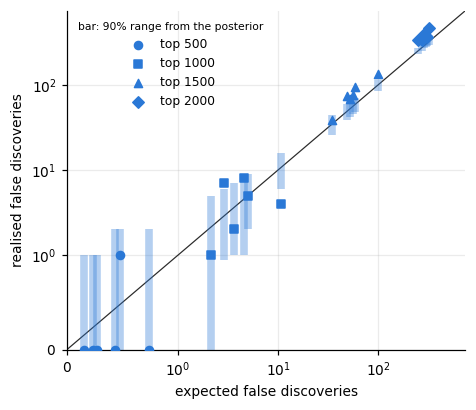

In [11]:
fig, ax = plt.subplots(figsize=(4.4, 3.8))
lim = max(efd.hi.max(), efd.realised.max()) * 1.6
ax.plot([0, lim], [0, lim], color=INK, lw=0.8)
for k, m in zip((500, 1000, 1500, 2000), ("o", "s", "^", "D")):
    d = efd[efd.k == k]
    ax.vlines(d.expected, d.lo, d.hi, color=BLUE, alpha=0.35, lw=5)
    ax.scatter(d.expected, d.realised, marker=m, color=BLUE, s=28, zorder=3, label=f"top {k}")
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="expected false discoveries", ylabel="realised false discoveries")
ax.legend(loc="upper left", fontsize=8, title="bar: 90% range from the posterior", title_fontsize=7); fig.tight_layout()

Counts in the top 500 and 1,000 fall inside their ranges. Deeper in the list, where weakly supported genes enter, the realised count is about a third higher than expected: the probabilities of those genes are somewhat overconfident.

## 7. Effect sizes

Posterior means move towards zero only when the evidence is weak. Points are planted genes from all six datasets.

RMSE of lfc_mean: all reported genes 0.23, planted genes 0.57


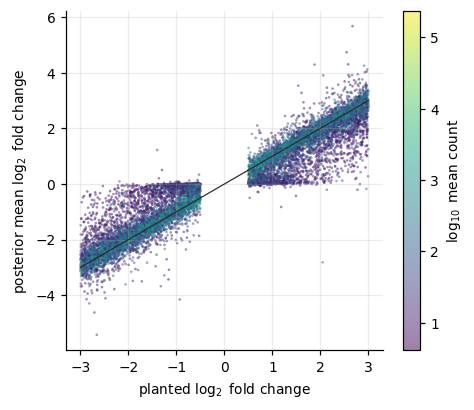

In [12]:
allres = pd.concat([run["res"] for run in runs])
de = allres[allres.expressed & (allres.theta != 0)]
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"RMSE of lfc_mean: all reported genes {rmse(allres.lfc_mean[allres.expressed], allres.theta[allres.expressed]):.2f}, "
      f"planted genes {rmse(de.lfc_mean, de.theta):.2f}")

fig, ax = plt.subplots(figsize=(4.4, 3.8))
sc = ax.scatter(de.theta, de.lfc_mean, c=np.log10(de.mean_count + 1), cmap="viridis", s=3, alpha=0.5, lw=0, rasterized=True)
ax.plot([-3, 3], [-3, 3], color=INK, lw=0.8)
ax.set(xlabel=r"planted $\log_2$ fold change", ylabel=r"posterior mean $\log_2$ fold change")
fig.colorbar(sc, label=r"$\log_{10}$ mean count"); fig.tight_layout()

## 8. Outlier counts

2% of all counts are multiplied 10–50-fold, as in the paper. The planted effects are the same as in Section 6.

In [13]:
def add_outliers(C, frac=0.02, seed=0):
    rng = np.random.default_rng(seed); C = C.copy(); hit = rng.random(C.shape) < frac
    C[hit] = (C[hit] * rng.uniform(10, 50, hit.sum())).astype(C.dtype)
    return C

out = []
for i, run in enumerate(runs):
    ro = analyse(add_outliers(run["counts"], seed=i), c8, counts.index, run["theta"])
    for label, rp in (("clean", run["res"]), ("2% outliers", ro)):
        false = rp.theta.abs() <= 0.5
        for rule, call in (("Bayesian FDR 5%", preset.calls(rp, fdr=0.05, rule="bfdr")), ("P > 0.9", preset.calls(rp, rule="p"))):
            out.append(dict(data=label, rule=rule, rep=i, called=int(call.sum()), realised_fdr=false[call].mean()))
out = pd.DataFrame(out)
out.groupby(["rule", "data"], sort=False)[["called", "realised_fdr"]].mean().round(3)

,,called,realised_fdr
rule,data,,
Bayesian FDR 5%,clean,1566.667,0.067
P > 0.9,clean,1311.000,0.020
Bayesian FDR 5%,2% outliers,1349.333,0.058
P > 0.9,2% outliers,1086.833,0.016


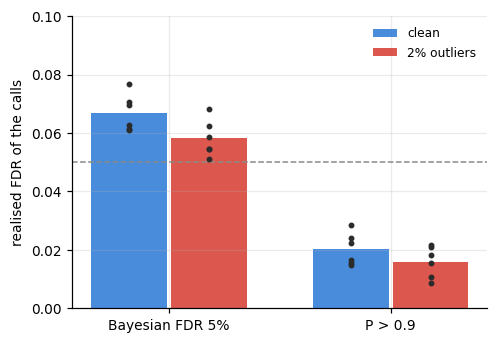

In [14]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
for j, rule in enumerate(out.rule.unique()):
    for k, (label, col) in enumerate((("clean", BLUE), ("2% outliers", RED))):
        d = out[(out.rule == rule) & (out.data == label)]; x = j + (k - 0.5) * 0.36
        ax.bar(x, d.realised_fdr.mean(), color=col, alpha=0.85, width=0.34, label=label if j == 0 else None)
        ax.scatter(np.full(len(d), x), d.realised_fdr, color=INK, s=8, zorder=3)
ax.axhline(0.05, color=GREY, ls="--", lw=1)
ax.set(xticks=[0, 1], xticklabels=out.rule.unique(), ylabel="realised FDR of the calls", ylim=(0, max(0.1, out.realised_fdr.max() * 1.3)))
ax.legend(loc="upper right", fontsize=8); fig.tight_layout()

## 9. Agreement with the rest of the cohort

The remaining 34 healthy and 24 psoriasis samples give a reference without any DE tool: the observed $\log_2$ ratio of mean normalised counts. We compare it with what a user would compute from the 4 vs 4 study: the raw ratio, and PRESET.

In [15]:
def size_factors(C):                                       # median-of-ratios normalisation
    lg = np.log(C.where(C > 0)); return np.exp(lg.sub(lg.mean(1), axis=0).median())

def log_ratio(C, case, ctrl):
    N = C / size_factors(C); return np.log2(N[case].mean(1) + 1) - np.log2(N[ctrl].mean(1) + 1)

reference = log_ratio(counts[list(healthy[4:]) + list(psoriasis[4:])], psoriasis[4:], healthy[4:])
raw_4v4 = log_ratio(counts[study], psoriasis[:4], healthy[:4])

cmp = res[expressed].set_index("gene")[["lfc_mean", "lfc_given_de", "p_de"]].join(
    pd.DataFrame({"reference": reference, "raw_4v4": raw_4v4}), how="inner")
cmp["called"] = preset.calls(res, fdr=0.05)[expressed]
confirmed = (np.sign(cmp.lfc_mean) == np.sign(cmp.reference)) & (cmp.reference.abs() > 0.5)
print(f"RMSE against the reference: raw 4 vs 4 {rmse(cmp.raw_4v4, cmp.reference):.2f}, PRESET {rmse(cmp.lfc_mean, cmp.reference):.2f}")
print(f"called genes confirmed by the reference (same sign, |log2FC| > 0.5): {confirmed[cmp.called].mean():.1%} of {cmp.called.sum():,}")
cmp["bayes"] = preset.calls(res, fdr=0.05, rule="bfdr")[expressed]
print(f"Bayesian-FDR calls confirmed: {confirmed[cmp.bayes].mean():.1%} of {cmp.bayes.sum():,}; "
      f"of the {(cmp.called & ~cmp.bayes).sum():,} genes called only by the target-decoy rule, {confirmed[cmp.called & ~cmp.bayes].mean():.1%}")

RMSE against the reference: raw 4 vs 4 0.46, PRESET 0.44
called genes confirmed by the reference (same sign, |log2FC| > 0.5): 97.3% of 3,442
Bayesian-FDR calls confirmed: 98.0% of 3,076; of the 476 genes called only by the target-decoy rule, 90.8%


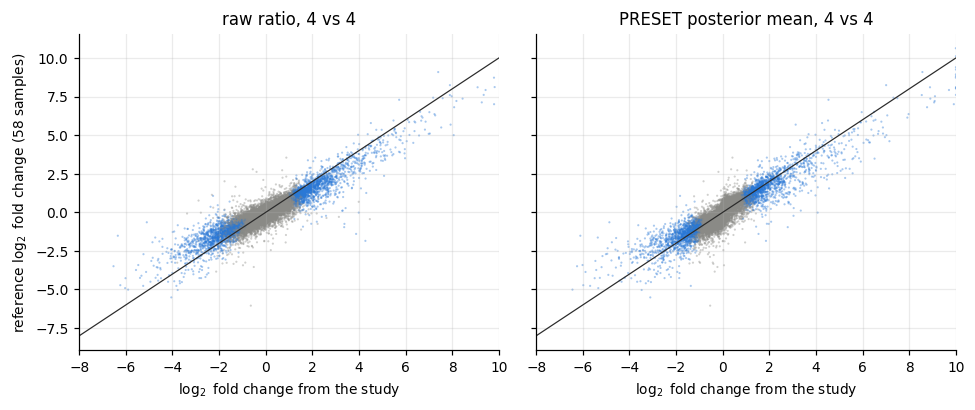

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, col, title in ((axes[0], "raw_4v4", "raw ratio, 4 vs 4"), (axes[1], "lfc_mean", "PRESET posterior mean, 4 vs 4")):
    ax.scatter(cmp[col], cmp.reference, s=2, c=np.where(cmp.called, BLUE, GREY), alpha=0.4, lw=0, rasterized=True)
    ax.plot([-8, 10], [-8, 10], color=INK, lw=0.8)
    ax.set(title=title, xlabel=r"$\log_2$ fold change from the study", xlim=(-8, 10))
axes[0].set_ylabel(r"reference $\log_2$ fold change (58 samples)"); fig.tight_layout()

## 10. Pathways

Over-representation of the MSigDB Hallmark gene sets among the up- and down-regulated genes called from the 4 vs 4 study, compared with the same test on the rest of the cohort (genes with |log2FC| > 1 in the 58 remaining samples). No pathway labels are needed.

In [17]:
from scipy.stats import hypergeom
hallmark = {l.split("\t")[0]: set(x for x in l.rstrip("\n").split("\t")[2:] if x) for l in open("data/MSigDB_Hallmark_2020.gmt")}

def enrich(genes, universe, sets):
    rows = [(name, len(S & universe & genes), len(S & universe)) for name, S in sets.items() if len(S & universe) >= 10]
    t = pd.DataFrame(rows, columns=["pathway", "hits", "size"])
    t["p"] = hypergeom.sf(t.hits - 1, len(universe), t["size"], len(genes))
    t = t.sort_values("p"); t["q"] = np.minimum.accumulate((t.p * len(t) / np.arange(1, len(t) + 1))[::-1])[::-1].clip(upper=1)
    return t.set_index("pathway").q

universe = set(cmp.index)
rows = []
for direction, sign in (("up", 1), ("down", -1)):
    q_study = enrich(set(cmp.index[cmp.called & (np.sign(cmp.lfc_mean) == sign)]), universe, hallmark)
    q_rest = enrich(set(cmp.index[cmp.reference * sign > 1]), universe, hallmark)
    rows.append(pd.DataFrame({"direction": direction, "q_4v4": q_study, "q_rest_of_cohort": q_rest.reindex(q_study.index)}))
pw = pd.concat(rows)
found, confirmed = pw.q_4v4 < 0.05, (pw.q_4v4 < 0.05) & (pw.q_rest_of_cohort < 0.05)
print(f"pathways found from the 4 vs 4 study: {found.sum()}, also found in the rest of the cohort: {confirmed.sum()}")
pw[found].sort_values("q_4v4").head(12).style.format({"q_4v4": "{:.1e}", "q_rest_of_cohort": "{:.1e}"})

pathways found from the 4 vs 4 study: 30, also found in the rest of the cohort: 27


,direction,q_4v4,q_rest_of_cohort
pathway,,,
Interferon Gamma Response,up,6.2e-44,3.1e-38
Inflammatory Response,up,1.5e-32,3.2e-25
Interferon Alpha Response,up,1.1e-31,8.3e-30
Allograft Rejection,up,2.0e-25,9.1e-25
TNF-alpha Signaling via NF-kB,up,4.9e-21,1.2e-17
G2-M Checkpoint,up,8.8e-20,2.2e-13
IL-6/JAK/STAT3 Signaling,up,5.1e-18,6.7e-14
E2F Targets,up,2.1e-16,3.1e-12
IL-2/STAT5 Signaling,up,1.0e-09,2.0e-10


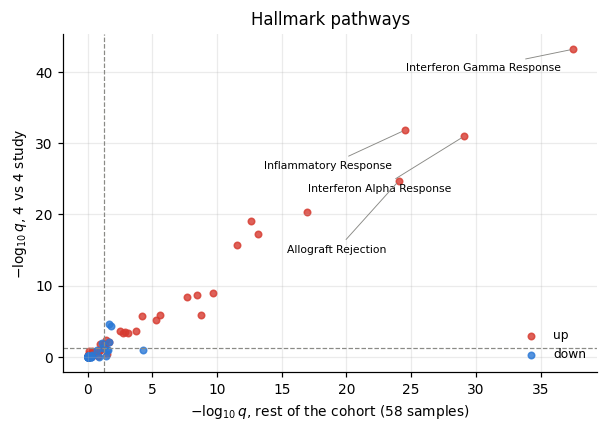

In [18]:
fig, ax = plt.subplots(figsize=(5.6, 4.0))
lq = lambda q: -np.log10(np.maximum(q, 1e-300))
for direction, col in (("up", RED), ("down", BLUE)):
    d = pw[pw.direction == direction]
    ax.scatter(lq(d.q_rest_of_cohort), lq(d.q_4v4), s=18, color=col, alpha=0.8, label=direction)
top = pw[found].sort_values("q_4v4").head(4)
for k, (name, r) in enumerate(top.iterrows()):
    ax.annotate(name, (lq(r.q_rest_of_cohort), lq(r.q_4v4)), xytext=(-8, -14 - 11 * k), textcoords="offset points", ha="right", fontsize=7,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.6))
ax.axhline(lq(0.05), color=GREY, ls="--", lw=0.8); ax.axvline(lq(0.05), color=GREY, ls="--", lw=0.8)
ax.set(xlabel=r"$-\log_{10} q$, rest of the cohort (58 samples)", ylabel=r"$-\log_{10} q$, 4 vs 4 study", title="Hallmark pathways")
ax.legend(loc="lower right", fontsize=8); fig.tight_layout()

## 11. Volcano plot and gene embedding

Two plotting helpers come with the package (`pip install "preset[plot]"`; maps use UMAP when `umap-learn` is installed, otherwise the first two principal components). The volcano plot shows the posterior mean log2 fold change against $P(|\log_2\mathrm{FC}| > 0.5)$, colours the called genes and names those with the largest changes:

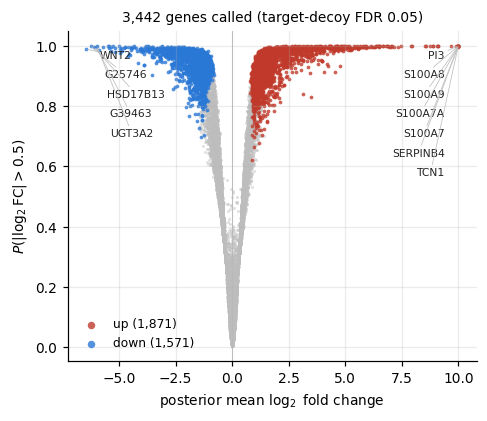

In [19]:
ax = preset.plot.volcano(res, label=12)

`preset.embed` returns, for every gene, the 128-dimensional vector the network computes in this dataset, after the genes have exchanged information; it is the input of the posterior head. Pass the same matrix as to `preset.run`. Genes close together on the map are genes the network treats alike here. This is a descriptive view, not a validated measure of co-regulation.

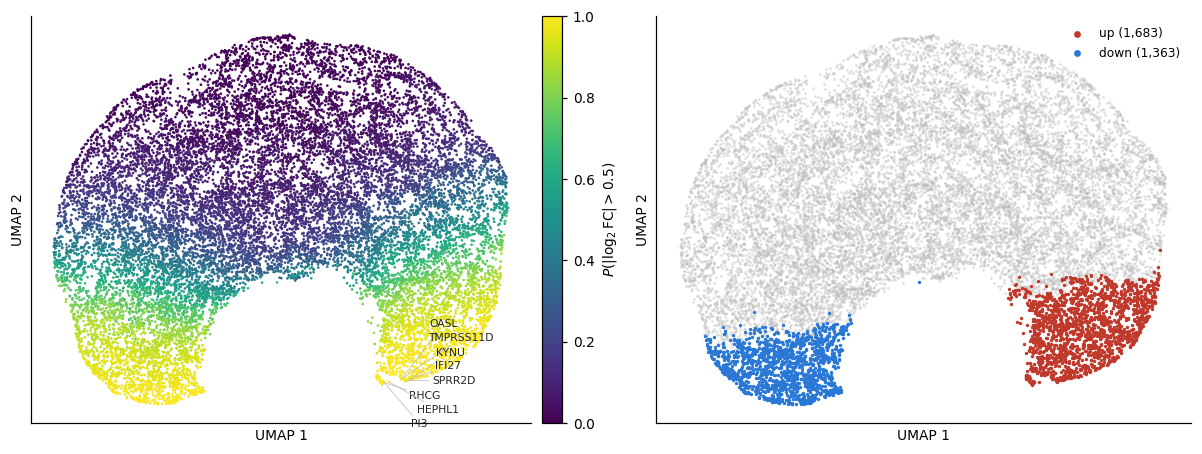

In [20]:
emb = preset.embed(X, cond, model=model)            # genes x 128, rows in the order of X's columns
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
preset.plot.embedding(emb, res, color="p_de", min_mean_count=10, label=8, ax=a)
preset.plot.embedding(emb, res, color="called", min_mean_count=10, ax=b)
fig.tight_layout()

To group genes, cluster the embedding of the reported genes, for example with k-means:

In [21]:
from sklearn.cluster import KMeans
keep = (res["rank"].notna() & (res.mean_count >= 10)).to_numpy()
groups = KMeans(20, n_init=4, random_state=0).fit_predict(emb[keep])
summary = (res[keep].assign(group=groups).groupby("group")
           .agg(genes=("gene", "size"), mean_p_de=("p_de", "mean"), share_up=("lfc_mean", lambda v: (v > 0.5).mean()), share_down=("lfc_mean", lambda v: (v < -0.5).mean())))
summary.sort_values("mean_p_de", ascending=False).head(6).round(2)

,genes,mean_p_de,share_up,share_down
group,,,,
10,236,0.99,1.00,0.0
9,625,0.98,1.00,0.0
2,555,0.97,0.00,1.0
8,833,0.92,0.00,1.0
15,594,0.85,1.00,0.0
12,967,0.79,0.99,0.0


Groups formed this way mostly gather genes with similar evidence and direction of change. In our checks they shared Hallmark pathways more often than random groups but no more often than k-means groups of the genes' own expression profiles, so read them as a summary of the result, not as gene modules.

## 12. Scope and self-check

- Trained on 2–16 samples per group; **at least 4 per group** recommended. The ranking was evaluated up to 100 and the default calls from 4 to 50 samples per group.
- Two groups, plus one optional two-level batch column: `preset.run(X, cond, batch=b)` with `b` in {0, 1}.
- Pass every gene with a count; `preset.io.prepare` chooses which ones the model sees and which ones are reported.
- `tau` sets the effect size that counts as a change (default $|\log_2\mathrm{FC}| > 0.5$). The calling rules were validated at the default.
- Covariates and paired designs (`preset.io.build_covariates`) are experimental.

`preset.diagnose` splits one group at random and reruns the model; any call there is a false positive. It also reports the log2 ratio of the groups' sequencing depths: decoys move raw counts between samples, so beyond 0.3 in absolute value the target-decoy cut-off becomes conservative and is flagged.

In [22]:
d = preset.diagnose(X, cond, model=model)
{k: d[k] for k in ("null_split_fraction_called", "within_group_pc1_share", "median_library", "log2_depth_ratio", "flags")}

{'null_split_fraction_called': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  3.884852958315528e-05,
  0.0,
  0.0],
 'within_group_pc1_share': 0.2863699290604056,
 'median_library': 17470169,
 'log2_depth_ratio': 0.31725966371698955,
 'flags': ['unequal sequencing depth between groups (log2 size-factor ratio +0.32): the decoy cut-off is conservative here and may call too few genes; rely on ranking / expected false discoveries']}

This study is flagged: the psoriasis samples have about 1.25 times the sequencing depth of the healthy ones. The target-decoy list of Section 5 is therefore, if anything, too short; the ranking and the posterior are not affected.

**Command line**

```bash
preset run counts.tsv samples.tsv --condition group --control healthy --case psoriasis --out results.tsv   # --rule auto (default)
preset run counts.tsv samples.tsv --condition group --control healthy --case psoriasis --out results.tsv --volcano volcano.png --embed embedding.tsv
preset run counts.tsv samples.tsv --condition group --control healthy --case psoriasis --rule bfdr --out results_bfdr.tsv   # Bayesian FDR only (one pass)
preset diagnose counts.tsv samples.tsv --condition group
```

**Citation.** Jang J, Jung I. PRESET: differential expression with a prior learned across RNA-seq experiments. 2026.